In [3]:
from google.colab import files
import zipfile

uploaded = files.upload()
zip_name = list(uploaded.keys())[0]   # whatever name Colab saved it under
print("Using:", zip_name)

with zipfile.ZipFile(zip_name) as z:
    z.extractall("data")

!ls data

Saving KDDTrain+_20Percent.zip to KDDTrain+_20Percent (2).zip
Using: KDDTrain+_20Percent (2).zip
KDDTest+.txt  KDDTrain+_20Percent.txt


In [4]:
import pandas as pd

cols = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in",
    "num_compromised","root_shell","su_attempted","num_root","num_file_creations",
    "num_shells","num_access_files","num_outbound_cmds","is_host_login",
    "is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
    "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
    "srv_diff_host_rate","dst_host_count","dst_host_srv_count",
    "dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate",
    "dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate",
    "dst_host_srv_rerror_rate","label","difficulty"
]

train = pd.read_csv("data/KDDTrain+_20Percent.txt", names=cols)
test  = pd.read_csv("data/KDDTest+.txt", names=cols)

print(train.shape, test.shape)
train.head()

(25192, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:
print(train["label"].value_counts().head(10))
print()
print(train["protocol_type"].value_counts())
print()
print(train.isnull().sum().sum(), "missing values")

label
normal         13449
neptune         8282
ipsweep          710
satan            691
portsweep        587
smurf            529
nmap             301
back             196
teardrop         188
warezclient      181
Name: count, dtype: int64

protocol_type
tcp     20526
udp      3011
icmp     1655
Name: count, dtype: int64

0 missing values


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Binary labels: 0 = normal, 1 = attack
y_train = (train["label"] != "normal").astype(int)
y_test  = (test["label"]  != "normal").astype(int)

# 2. Features only (drop the label and the difficulty score)
X_train = train.drop(columns=["label", "difficulty"])
X_test  = test.drop(columns=["label", "difficulty"])

# 3. Encode categoricals, scale numerics
cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
])

X_train_p = preprocess.fit_transform(X_train)   # learn from train only
X_test_p  = preprocess.transform(X_test)        # apply the same rules to test

print("Train:", X_train_p.shape, "| Test:", X_test_p.shape)
print("Attack share in train:", round(y_train.mean(), 3))
print("Attack share in test: ", round(y_test.mean(), 3))

Train: (25192, 118) | Test: (22544, 118)
Attack share in train: 0.466
Attack share in test:  0.569


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(X_train_p, y_train)
    preds = model.predict(X_test_p)
    print("=" * 50)
    print(name)
    print(classification_report(y_test, preds, target_names=["normal", "attack"]))
    print("Confusion matrix (rows = actual, cols = predicted):")
    print(confusion_matrix(y_test, preds))

Logistic Regression
              precision    recall  f1-score   support

      normal       0.65      0.93      0.76      9711
      attack       0.92      0.62      0.74     12833

    accuracy                           0.75     22544
   macro avg       0.78      0.77      0.75     22544
weighted avg       0.80      0.75      0.75     22544

Confusion matrix (rows = actual, cols = predicted):
[[8993  718]
 [4900 7933]]
Decision Tree
              precision    recall  f1-score   support

      normal       0.71      0.96      0.82      9711
      attack       0.96      0.70      0.81     12833

    accuracy                           0.81     22544
   macro avg       0.83      0.83      0.81     22544
weighted avg       0.85      0.81      0.81     22544

Confusion matrix (rows = actual, cols = predicted):
[[9335  376]
 [3814 9019]]


In [8]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_p, y_train)
rf_preds = rf.predict(X_test_p)

print(classification_report(y_test, rf_preds, target_names=["normal", "attack"]))
print(confusion_matrix(y_test, rf_preds))

# Which attack types does the model miss?
results = test[["label"]].copy()
results["detected"] = (rf_preds == 1)
attacks = results[results["label"] != "normal"]

breakdown = (attacks.groupby("label")["detected"]
             .agg(["count", "mean"])
             .rename(columns={"count": "samples", "mean": "detection_rate"})
             .sort_values("samples", ascending=False))

# Mark attack types that never appear in training
breakdown["in_train"] = breakdown.index.isin(train["label"].unique())
print(breakdown.head(15))

              precision    recall  f1-score   support

      normal       0.67      0.97      0.79      9711
      attack       0.97      0.63      0.76     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.78     22544
weighted avg       0.84      0.78      0.77     22544

[[9447  264]
 [4758 8075]]
               samples  detection_rate  in_train
label                                           
neptune           4657        0.999571      True
guess_passwd      1231        0.000000      True
mscan              996        0.319277     False
warezmaster        944        0.241525      True
apache2            737        0.502035     False
satan              735        0.998639      True
processtable       685        0.000000     False
smurf              665        1.000000      True
back               359        0.994429      True
snmpguess          331        0.000000     False
saint              319        0.978056     False
mailbomb 

In [9]:
# 1. How many examples of each missed attack did the model see in training?
check = ["guess_passwd", "warezmaster", "mscan", "apache2"]
print(train["label"].value_counts().reindex(check))

# 2. Group attacks into the standard four NSL-KDD categories
categories = {
    "DoS":   ["neptune","smurf","back","teardrop","pod","land","apache2",
              "processtable","mailbomb","udpstorm"],
    "Probe": ["satan","ipsweep","nmap","portsweep","mscan","saint"],
    "R2L":   ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster",
              "warezclient","spy","xlock","xsnoop","snmpguess","snmpgetattack",
              "httptunnel","sendmail","named","worm"],
    "U2R":   ["buffer_overflow","loadmodule","rootkit","perl","sqlattack",
              "xterm","ps"],
}
label_to_cat = {l: c for c, labels in categories.items() for l in labels}

attacks = attacks.copy()
attacks["category"] = attacks["label"].map(label_to_cat)
print(attacks.groupby("category")["detected"].agg(["count", "mean"]))

label
guess_passwd    10.0
warezmaster      7.0
mscan            NaN
apache2          NaN
Name: count, dtype: float64
          count      mean
category                 
DoS        7458  0.818182
Probe      2421  0.716233
R2L        2887  0.081053
U2R          67  0.074627


In [13]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving KDDTrain+.txt to KDDTrain+.txt
['KDDTrain+.txt']


In [14]:
train_full = pd.read_csv("KDDTrain+.txt", names=cols)
print(train_full.shape)   # expect about (125973, 43)

(125973, 43)


In [15]:
categories = {
    "DoS":   ["neptune","smurf","back","teardrop","pod","land","apache2",
              "processtable","mailbomb","udpstorm"],
    "Probe": ["satan","ipsweep","nmap","portsweep","mscan","saint"],
    "R2L":   ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster",
              "warezclient","spy","xlock","xsnoop","snmpguess","snmpgetattack",
              "httptunnel","sendmail","named","worm"],
    "U2R":   ["buffer_overflow","loadmodule","rootkit","perl","sqlattack",
              "xterm","ps"],
}
label_to_cat = {l: c for c, labels in categories.items() for l in labels}

In [16]:
from sklearn.ensemble import RandomForestClassifier

print(train_full["label"].value_counts().reindex(["guess_passwd", "warezmaster"]))

X_tr = train_full.drop(columns=["label", "difficulty"])
y_tr = (train_full["label"] != "normal").astype(int)

X_tr_p = preprocess.fit_transform(X_tr)
X_te_p = preprocess.transform(X_test)

rf_full = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_full.fit(X_tr_p, y_tr)
full_preds = rf_full.predict(X_te_p)

res = test[["label"]].copy()
res["detected"] = (full_preds == 1)
res = res[res["label"] != "normal"].copy()
res["category"] = res["label"].map(label_to_cat)
print(res.groupby("category")["detected"].agg(["count", "mean"]))

label
guess_passwd    53
warezmaster     20
Name: count, dtype: int64
          count      mean
category                 
DoS        7458  0.828238
Probe      2421  0.722016
R2L        2887  0.058538
U2R          67  0.134328


   threshold  attack_recall  attack_precision  false_alarm_rate
0       0.50          0.633             0.969             0.027
1       0.40          0.678             0.969             0.028
2       0.30          0.722             0.968             0.032
3       0.20          0.781             0.935             0.072
4       0.10          0.879             0.923             0.098
5       0.05          0.930             0.919             0.108
6       0.02          0.976             0.911             0.125


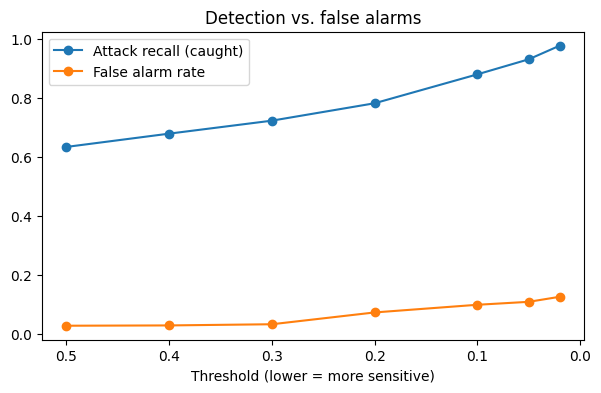

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

# Probability of "attack" for each test connection
probs = rf_full.predict_proba(X_te_p)[:, 1]

rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05, 0.02]:
    preds = (probs >= t).astype(int)
    false_alarm_rate = ((preds == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
    rows.append({
        "threshold": t,
        "attack_recall": recall_score(y_test, preds),
        "attack_precision": precision_score(y_test, preds),
        "false_alarm_rate": false_alarm_rate,
    })

sweep = pd.DataFrame(rows).round(3)
print(sweep)

plt.figure(figsize=(7, 4))
plt.plot(sweep["threshold"], sweep["attack_recall"], marker="o", label="Attack recall (caught)")
plt.plot(sweep["threshold"], sweep["false_alarm_rate"], marker="o", label="False alarm rate")
plt.xlabel("Threshold (lower = more sensitive)")
plt.legend()
plt.title("Detection vs. false alarms")
plt.gca().invert_xaxis()
plt.show()

In [18]:
t = 0.1   # change this after you look at the table above

preds_t = (probs >= t).astype(int)
res_t = test[["label"]].copy()
res_t["detected"] = (preds_t == 1)
res_t = res_t[res_t["label"] != "normal"].copy()
res_t["category"] = res_t["label"].map(label_to_cat)
print(f"Threshold = {t}")
print(res_t.groupby("category")["detected"].agg(["count", "mean"]))

Threshold = 0.1
          count      mean
category                 
DoS        7458  0.961786
Probe      2421  1.000000
R2L        2887  0.565639
U2R          67  0.761194


In [19]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Attack types hidden from training, spread across families
holdout = ["nmap", "teardrop", "warezclient", "pod"]
is_hold = train_full["label"].isin(holdout)

rest = train_full[~is_hold]
sub_train, rest_val = train_test_split(
    rest, test_size=0.2, random_state=42,
    stratify=(rest["label"] != "normal"))

# Validation = a normal/known-attack slice + the hidden attack types
val = pd.concat([rest_val, train_full[is_hold]])

def split_xy(df):
    return df.drop(columns=["label", "difficulty"]), (df["label"] != "normal").astype(int)

X_sub, y_sub = split_xy(sub_train)
X_val, y_val = split_xy(val)

# Fresh preprocessing, fit on the reduced training set only
prep = clone(preprocess)
X_sub_p  = prep.fit_transform(X_sub)
X_val_p  = prep.transform(X_val)
X_test_p2 = prep.transform(X_test)

rf_v = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_v.fit(X_sub_p, y_sub)
val_probs = rf_v.predict_proba(X_val_p)[:, 1]

unseen = val["label"].isin(holdout).values
is_attack = (y_val == 1).values
is_normal = (y_val == 0).values

rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05, 0.02]:
    p = val_probs >= t
    rows.append({
        "threshold": t,
        "recall_all_attacks": p[is_attack].mean(),
        "recall_unseen_attacks": p[unseen].mean(),
        "false_alarm_rate": p[is_normal].mean(),
    })

val_sweep = pd.DataFrame(rows).round(3)
print(val_sweep)

   threshold  recall_all_attacks  recall_unseen_attacks  false_alarm_rate
0       0.50               0.884                  0.520             0.000
1       0.40               0.909                  0.623             0.001
2       0.30               0.919                  0.663             0.001
3       0.20               0.921                  0.673             0.002
4       0.10               0.928                  0.702             0.006
5       0.05               0.937                  0.738             0.012
6       0.02               0.954                  0.808             0.028


In [20]:
# Rule, decided before touching the test set:
# among thresholds with false alarm rate <= 5% on validation,
# take the one that catches the most unseen attacks
ok = val_sweep[val_sweep["false_alarm_rate"] <= 0.05]
chosen = ok.sort_values("recall_unseen_attacks", ascending=False).iloc[0]["threshold"]
print("Chosen threshold:", chosen)

# Single evaluation on the test set
test_probs = rf_v.predict_proba(X_test_p2)[:, 1]
test_preds = (test_probs >= chosen).astype(int)

print("Test attack recall:  ", round(recall_score(y_test, test_preds), 3))
print("Test precision:      ", round(precision_score(y_test, test_preds), 3))
print("Test false alarm rate:",
      round(((test_preds == 1) & (y_test == 0)).sum() / (y_test == 0).sum(), 3))

res_v = test[["label"]].copy()
res_v["detected"] = (test_preds == 1)
res_v = res_v[res_v["label"] != "normal"].copy()
res_v["category"] = res_v["label"].map(label_to_cat)
print(res_v.groupby("category")["detected"].agg(["count", "mean"]))

Chosen threshold: 0.02
Test attack recall:   0.949
Test precision:       0.911
Test false alarm rate: 0.123
          count      mean
category                 
DoS        7458  0.988469
Probe      2421  1.000000
R2L        2887  0.808105
U2R          67  0.865672
